# Member 1 — Hotel Booking Cancellation: EDA & Visualization
**IT3051 – Fundamentals of Data Mining**

**Question:** What does the dataset tell us, and which patterns are associated with cancellation?

This notebook covers Member 1’s Stage 1 contribution: inspection, target analysis, distributions, relationships, quality observations, and handover notes. It does not clean the data or train a model. Logistic Regression belongs to the later modelling stage after the team agrees on preprocessing and validation.

Run the cells from top to bottom. Tables and figures are saved to `reports/member1/`. All findings describe this historical sample, not causal effects or guaranteed future behaviour. The dataset source and licence should be confirmed by the group before the final report; the supplied project summary is the current provenance reference.

## 1. Load the raw data
Use the project’s local Python environment. In Colab, the setup cell mounts Drive and uses your project path automatically. Approve the Drive connection when Colab asks. No personal computer path is required. A file fingerprint and an end-of-notebook check verify that this analysis leaves the raw CSV unchanged.

In [1]:
from pathlib import Path
import hashlib
import sys
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Mount Google Drive automatically when running in Colab.
DATA_PATH = None
try:
    from google.colab import drive
except ImportError:
    pass  # Local Jupyter / VS Code: locate the project below.
else:
    drive.mount('/content/drive')
    DATA_PATH = Path('/content/drive/MyDrive/hotel-booking-cancellation/data/raw/hotel_bookings.csv')
if DATA_PATH is None:
    root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                 if (p / 'data/raw/hotel_bookings.csv').exists()), None)
    if root is None:
        raise FileNotFoundError('Open this notebook inside the project or set DATA_PATH.')
    DATA_PATH = root / 'data/raw/hotel_bookings.csv'
else:
    DATA_PATH = Path(DATA_PATH).expanduser().resolve()
    root = DATA_PATH.parent.parent.parent
OUT = root / 'reports/member1'
FIGURES = OUT / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
raw_hash = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
df = pd.read_csv(DATA_PATH)
assert df['is_canceled'].notna().all() and set(df['is_canceled'].unique()) == {0, 1}
sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12})
def save_show(name):
    plt.tight_layout()
    plt.savefig(FIGURES / f'{name}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close()
def rate_table(column, frame=None):
    source = df if frame is None else frame
    result = source.groupby(column, dropna=False, observed=True)['is_canceled'].agg(
        bookings='size', canceled='sum')
    result['cancellation_pct'] = 100 * result['canceled'] / result['bookings']
    return result
print(f'Loaded {len(df):,} rows and {df.shape[1]} columns')
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__)
display(df.head())

Matplotlib is building the font cache; this may take a moment.


Loaded 119,390 rows and 32 columns
Python: 3.14.0 | pandas: 3.0.6


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Structure and variable meaning
Storage types and modelling roles differ: agent/company are identifiers, while binary indicators and calendar codes are not continuous measurements.

In [2]:
profile = pd.DataFrame({'dtype': df.dtypes.astype(str), 'unique_values': df.nunique(),
                        'missing': df.isna().sum(), 'missing_pct': df.isna().mean()*100})
profile.to_csv(OUT / 'column_profile.csv', index_label='column')
display(profile)
print('Numeric storage:', df.select_dtypes(include='number').columns.tolist())
print('Text/category storage:', df.select_dtypes(exclude='number').columns.tolist())
display(df.describe().T)
roles = {'target': ['is_canceled'], 'identifiers': ['agent', 'company'],
         'binary indicators': ['is_repeated_guest'],
         'calendar fields': [c for c in df if c.startswith('arrival_date')],
         'outcome / leakage review': ['reservation_status', 'reservation_status_date']}
display(pd.Series(roles, name='columns'))

,dtype,unique_values,missing,missing_pct
hotel,str,2,0,0.000000
is_canceled,int64,2,0,0.000000
lead_time,int64,479,0,0.000000
arrival_date_year,int64,3,0,0.000000
arrival_date_month,str,12,0,0.000000
arrival_date_week_number,int64,53,0,0.000000
arrival_date_day_of_month,int64,31,0,0.000000
stays_in_weekend_nights,int64,17,0,0.000000
stays_in_week_nights,int64,35,0,0.000000
adults,int64,14,0,0.000000


Numeric storage: ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']
Text/category storage: ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


target                                                          [is_canceled]
identifiers                                                  [agent, company]
binary indicators                                         [is_repeated_guest]
calendar fields             [arrival_date_year, arrival_date_month, arriva...
outcome / leakage review        [reservation_status, reservation_status_date]
Name: columns, dtype: object

## 3. Target balance
**Question:** How often are bookings cancelled? The denominator is all raw rows; no duplicates or unusual records have been removed.

,bookings,percentage
is_canceled,,
0,75166,62.958372
1,44224,37.041628


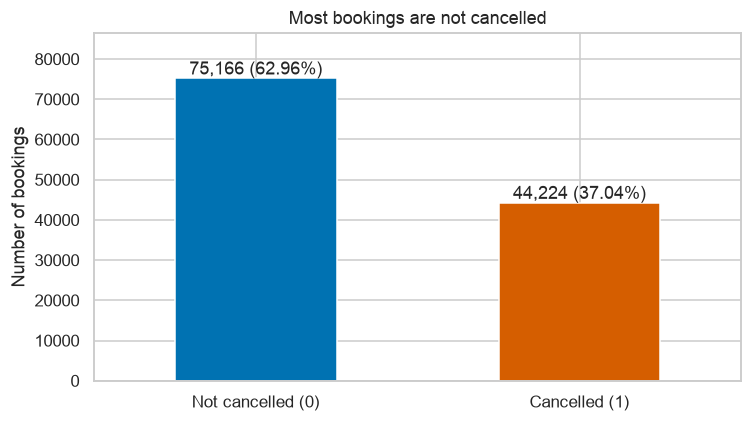

**Finding:** 37.04% of bookings were cancelled. Always predicting 'not cancelled' would achieve 62.96% accuracy on this sample. Later evaluation needs precision, recall, F1 and ROC-AUC alongside accuracy.

In [3]:
target = df['is_canceled'].value_counts().sort_index().rename_axis('is_canceled').to_frame('bookings')
target['percentage'] = target['bookings'] / len(df) * 100
display(target)
ax = target['bookings'].plot.bar(color=['#0072B2', '#D55E00'], figsize=(7,4), rot=0)
ax.set_xticklabels(['Not cancelled (0)', 'Cancelled (1)'])
ax.set(xlabel='', ylabel='Number of bookings', title='Most bookings are not cancelled')
for bar, pct in zip(ax.patches, target['percentage']):
    ax.annotate(f'{int(bar.get_height()):,} ({pct:.2f}%)',
                (bar.get_x()+bar.get_width()/2, bar.get_height()), ha='center', va='bottom')
ax.margins(y=0.15)
save_show('01_target_balance')
display(Markdown(f"**Finding:** {target.loc[1, 'percentage']:.2f}% of bookings were cancelled. "
                 f"Always predicting 'not cancelled' would achieve {target.loc[0, 'percentage']:.2f}% "
                 'accuracy on this sample. Later evaluation needs precision, recall, F1 and ROC-AUC alongside accuracy.'))

## 4. Missing values and data-quality observations
**Question:** What requires investigation by Member 2? These checks flag observations; they do not justify automatic deletion or imputation.

,missing,missing_pct
company,112593,94.306893
agent,16340,13.686238
country,488,0.408744
children,4,0.003350


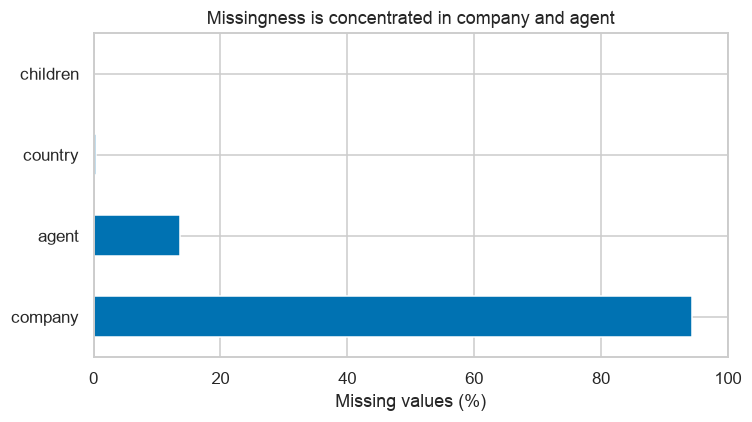

Exact duplicate rows beyond first occurrence    31994
Zero known total guests                           180
Unknown total guests due to missing inputs          4
Zero total nights                                 715
Negative ADR                                        1
Zero ADR                                         1959
Negative lead time                                  0
Negative guest or night counts                      0
Name: flagged_rows, dtype: int64

,outside_1_5_IQR
lead_time,3005
adr,3793
adults,29710
children,8590
babies,917
stays_in_weekend_nights,265
stays_in_week_nights,3354


,hotel,adr,adults,lead_time,is_canceled
48515,City Hotel,5400.0,2,35,1
111403,City Hotel,510.0,1,0,0
15083,Resort Hotel,508.0,2,1,0
103912,City Hotel,451.5,2,81,0
13142,Resort Hotel,450.0,2,378,1


In [4]:
missing = profile.loc[profile['missing'] > 0, ['missing', 'missing_pct']].sort_values('missing', ascending=False)
display(missing)
missing['missing_pct'].plot.barh(figsize=(7,4), color='#0072B2')
plt.xlabel('Missing values (%)'); plt.title('Missingness is concentrated in company and agent'); plt.xlim(0,100)
save_show('02_missing_values')
# Derived columns exist only in a separate exploratory copy.
eda = df.assign(total_stay=df['stays_in_weekend_nights'] + df['stays_in_week_nights'],
                total_guests=df[['adults','children','babies']].sum(axis=1, min_count=3))
quality = pd.Series({
    'Exact duplicate rows beyond first occurrence': int(df.duplicated().sum()),
    'Zero known total guests': int(eda['total_guests'].eq(0).sum()),
    'Unknown total guests due to missing inputs': int(eda['total_guests'].isna().sum()),
    'Zero total nights': int(eda['total_stay'].eq(0).sum()),
    'Negative ADR': int(df['adr'].lt(0).sum()),
    'Zero ADR': int(df['adr'].eq(0).sum()),
    'Negative lead time': int(df['lead_time'].lt(0).sum()),
    'Negative guest or night counts': int(df[['adults','children','babies','stays_in_week_nights','stays_in_weekend_nights']].lt(0).any(axis=1).sum()),
}, name='flagged_rows')
display(quality)
quality.to_csv(OUT / 'quality_flags.csv', index_label='check')
continuous = ['lead_time','adr','adults','children','babies','stays_in_weekend_nights','stays_in_week_nights']
q1, q3 = df[continuous].quantile(.25), df[continuous].quantile(.75)
iqr_flags = ((df[continuous] < q1-1.5*(q3-q1)) | (df[continuous] > q3+1.5*(q3-q1))).sum()
display(iqr_flags.to_frame('outside_1_5_IQR'))
display(df.nlargest(5, 'adr')[['hotel','adr','adults','lead_time','is_canceled']])

**Findings and handover:** `company` has 112,593 missing values (~94.31%); `agent` has 16,340, `country` 488 and `children` 4. Missing identifiers may indicate no company/agent, but this needs source confirmation. There are 31,994 repeated rows beyond their first occurrence; without a unique booking ID they are not automatically duplicate transactions. There are 180 rows with zero known guests, 715 zero-night stays and one negative ADR. Maximum ADR is 5,400 and maximum adults is 55. Ask Member 2 to investigate business meaning before changing any values. IQR flags are screening indicators, especially unreliable as deletion rules for sparse guest counts.

## 5. Numerical distributions and cancellation
**Question:** Are booking timing, price, and stay length distributed differently by outcome? Full ranges are retained below; the additional ADR zoom explicitly omits the upper 1% from that view only.

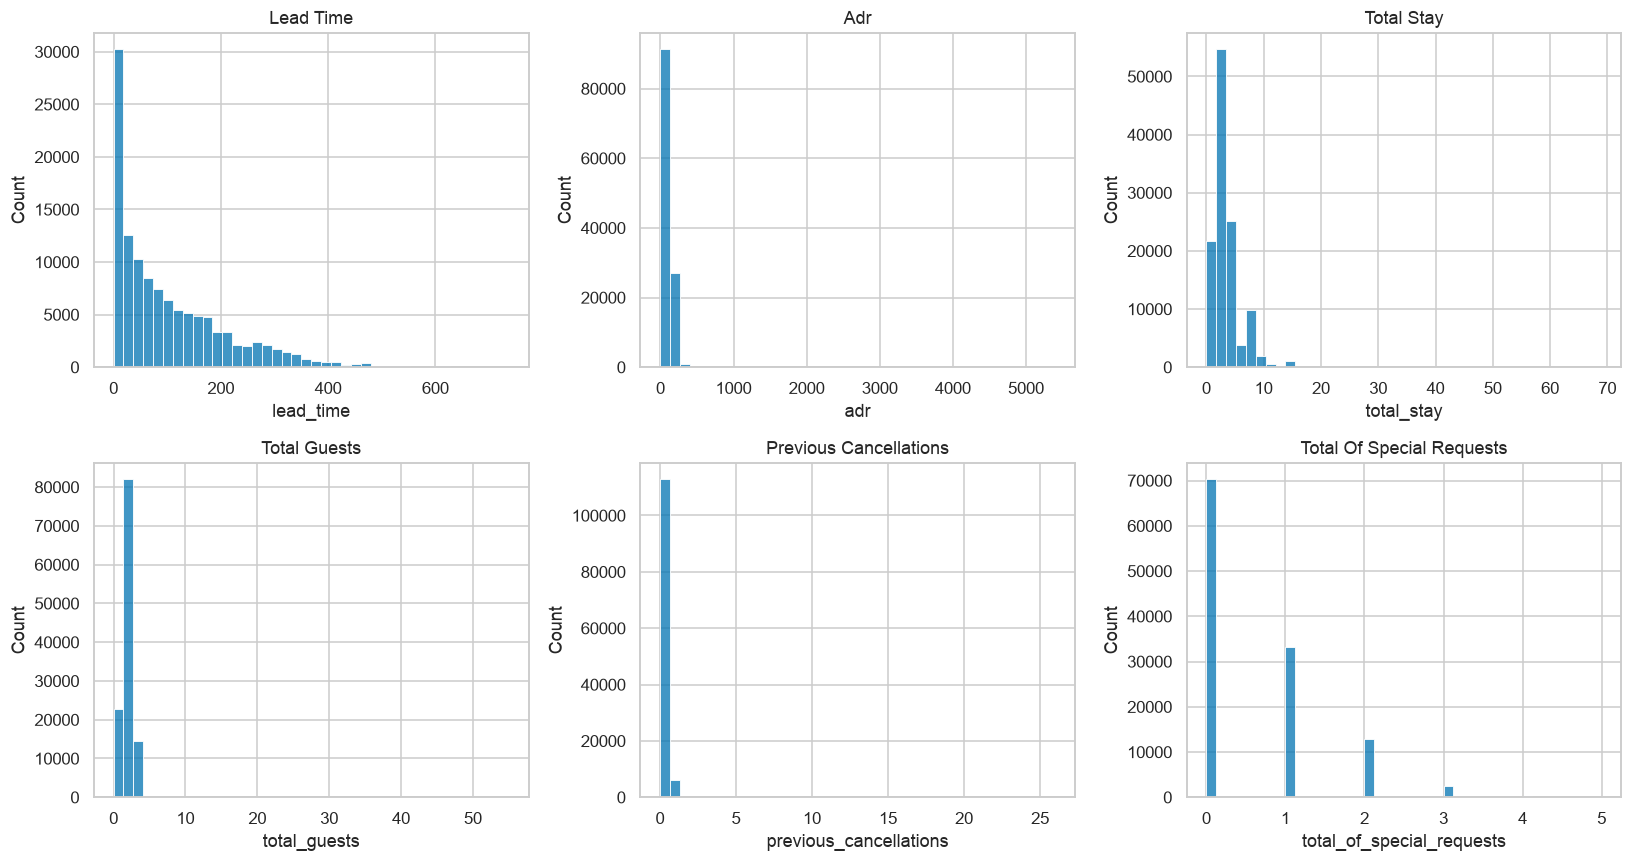

lead_time                adr             total_stay          
               median        mean median        mean     median      mean
is_canceled                                                              
0                45.0   79.984687   92.5   99.987693        3.0  3.393023
1               113.0  144.848815   96.2  104.964333        3.0  3.487179

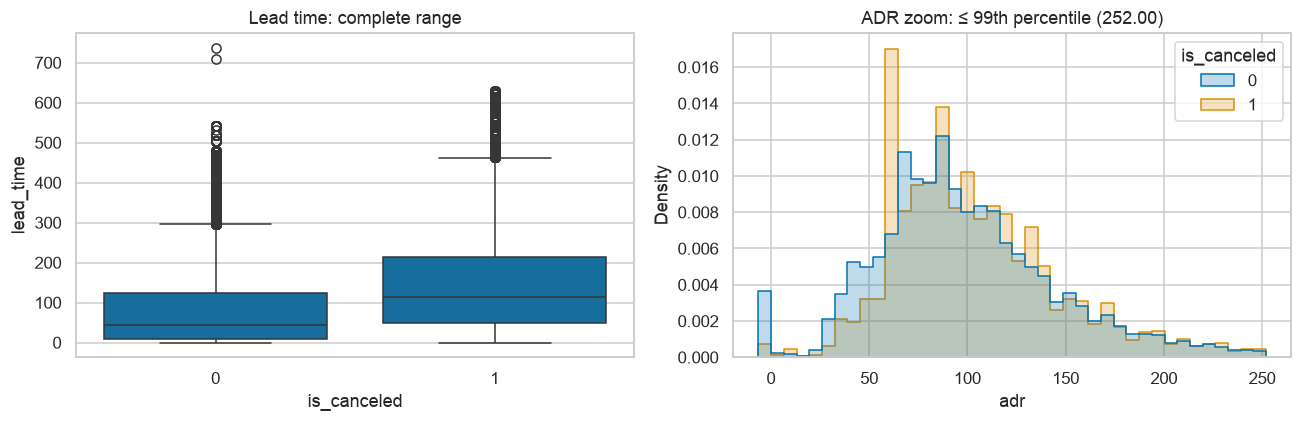

,bookings,canceled,cancellation_pct
lead_time_band,,,
0–7,19746,1902,9.632331
8–30,18960,5283,27.863924
31–90,29553,11141,37.698372
91–180,26439,11821,44.710466
181–365,21544,11947,55.453955
366+,3148,2130,67.662008


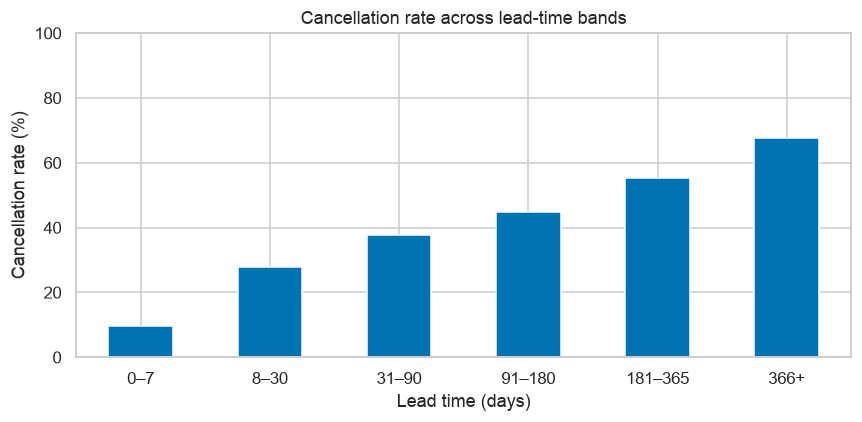

**Finding:** Median lead time is 113 days for cancelled bookings and 45 days for non-cancelled bookings. Lead time is worth passing to Member 4. ADR is right-skewed with an extreme upper value; Member 2 should validate it. These are associations, not causal effects.

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15,8))
for ax, col in zip(axes.flat, ['lead_time','adr','total_stay','total_guests','previous_cancellations','total_of_special_requests']):
    sns.histplot(data=eda, x=col, bins=40, ax=ax)
    ax.set_title(col.replace('_',' ').title())
save_show('03_numeric_distributions')
display(eda.groupby('is_canceled')[['lead_time','adr','total_stay']].agg(['median','mean']))
fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.boxplot(data=eda, x='is_canceled', y='lead_time', ax=axes[0], showfliers=True)
cap = df['adr'].quantile(.99)
sns.histplot(data=eda.loc[eda['adr'] <= cap], x='adr', hue='is_canceled', bins=40,
             stat='density', common_norm=False, element='step', ax=axes[1])
axes[0].set_title('Lead time: complete range')
axes[1].set_title(f'ADR zoom: ≤ 99th percentile ({cap:.2f})')
save_show('04_numeric_by_outcome')
eda['lead_time_band'] = pd.cut(eda['lead_time'], [-np.inf,7,30,90,180,365,np.inf],
                              labels=['0–7','8–30','31–90','91–180','181–365','366+'])
lead_rates = rate_table('lead_time_band', eda)
display(lead_rates)
lead_rates['cancellation_pct'].plot.bar(figsize=(8,4), rot=0)
plt.ylabel('Cancellation rate (%)'); plt.xlabel('Lead time (days)'); plt.ylim(0,100)
plt.title('Cancellation rate across lead-time bands')
save_show('05_lead_time_rates')
medians = eda.groupby('is_canceled')['lead_time'].median()
display(Markdown(f"**Finding:** Median lead time is {medians[1]:.0f} days for cancelled bookings "
                 f"and {medians[0]:.0f} days for non-cancelled bookings. Lead time is worth passing to Member 4. "
                 'ADR is right-skewed with an extreme upper value; Member 2 should validate it. These are associations, not causal effects.'))

## 6. Categorical patterns: counts and cancellation rates
**Question:** Which groups have higher observed cancellation rates, and how many bookings support each rate? Missing values remain a separate group. Rare categories can produce unstable percentages.

### hotel

,bookings,canceled,cancellation_pct
hotel,,,
City Hotel,79330,33102,41.73
Resort Hotel,40060,11122,27.76


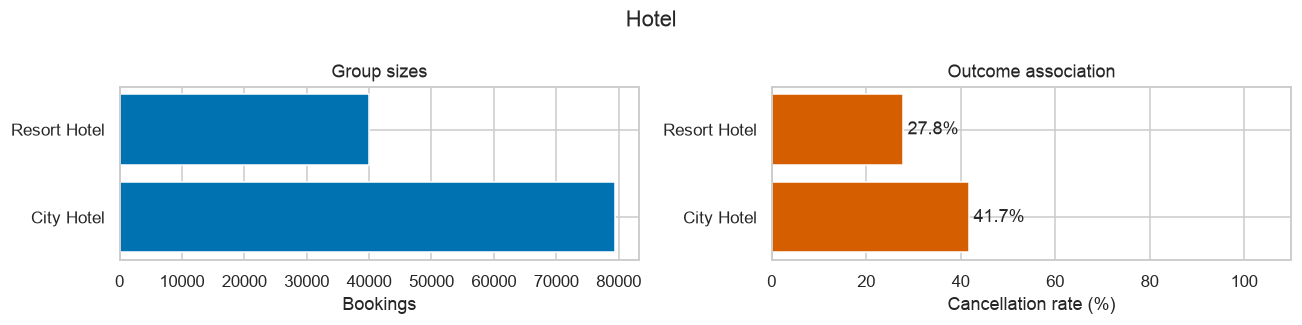

### deposit_type

,bookings,canceled,cancellation_pct
deposit_type,,,
No Deposit,104641,29694,28.38
Non Refund,14587,14494,99.36
Refundable,162,36,22.22


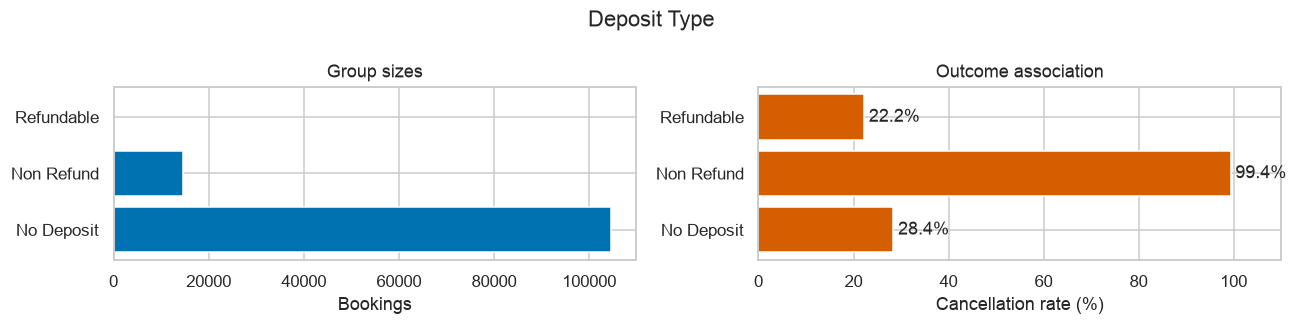

### market_segment

,bookings,canceled,cancellation_pct
market_segment,,,
Online TA,56477,20739,36.72
Offline TA/TO,24219,8311,34.32
Groups,19811,12097,61.06
Direct,12606,1934,15.34
Corporate,5295,992,18.73
Complementary,743,97,13.06
Aviation,237,52,21.94
Undefined,2,2,100.00


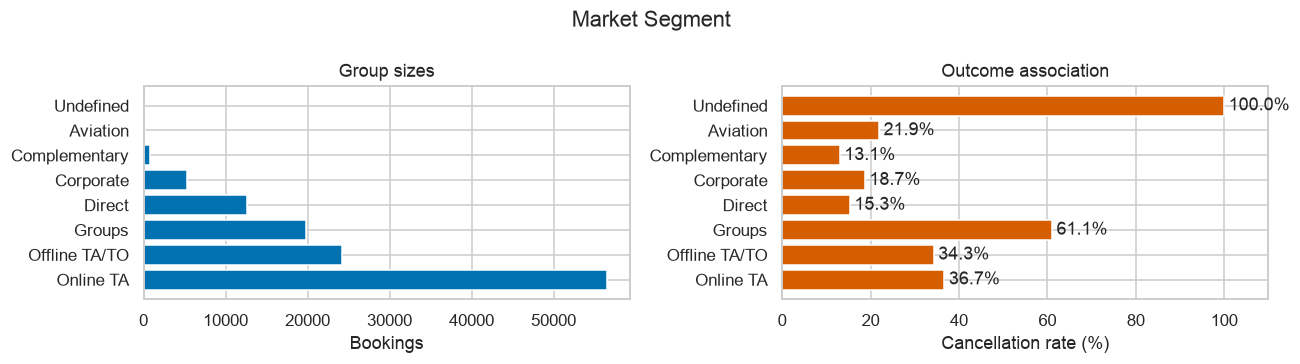

### customer_type

,bookings,canceled,cancellation_pct
customer_type,,,
Transient,89613,36514,40.75
Transient-Party,25124,6389,25.43
Contract,4076,1262,30.96
Group,577,59,10.23


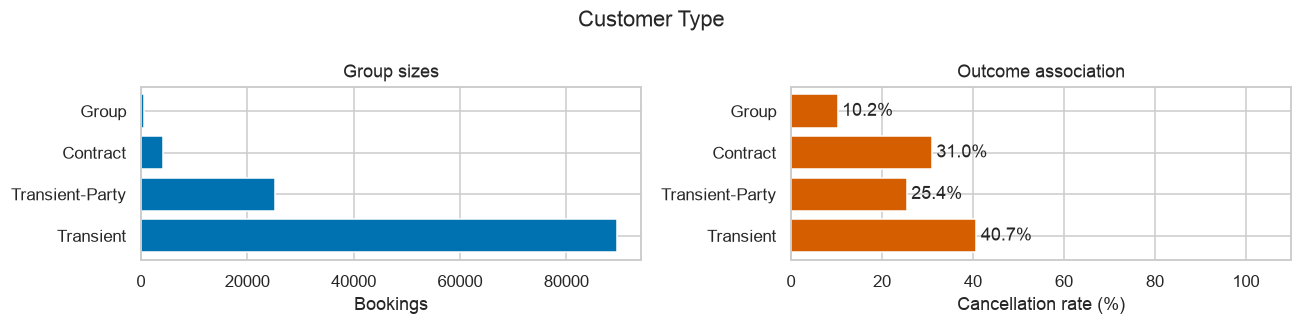

### is_repeated_guest

,bookings,canceled,cancellation_pct
is_repeated_guest,,,
0,115580,43672,37.79
1,3810,552,14.49


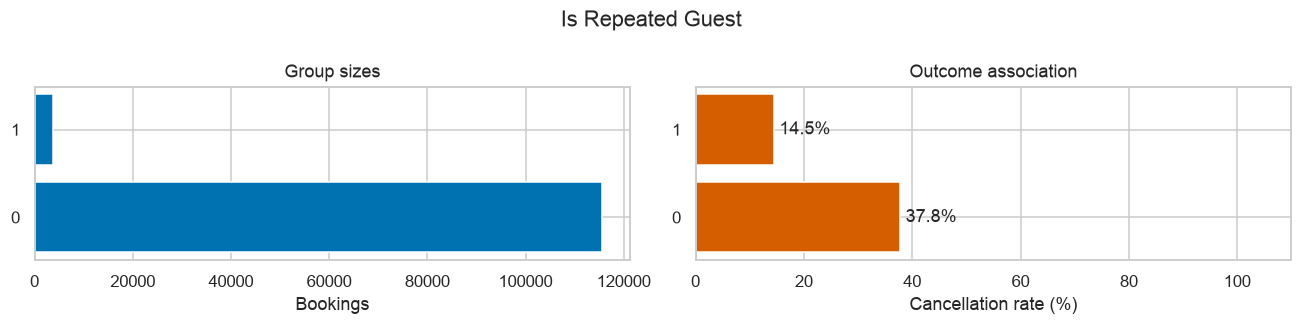

### total_of_special_requests

,bookings,canceled,cancellation_pct
total_of_special_requests,,,
0,70318,33556,47.72
1,33226,7318,22.02
2,12969,2866,22.10
3,2497,446,17.86
4,340,36,10.59
5,40,2,5.00


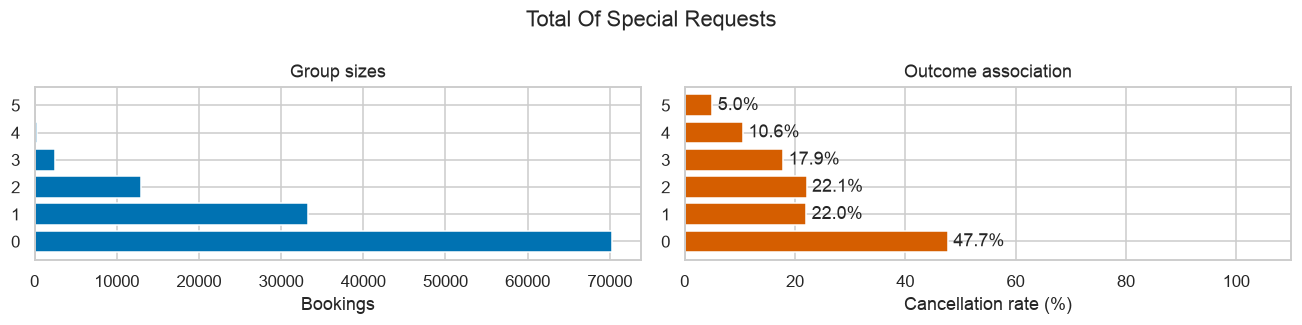

In [6]:
categorical_features = ['hotel','deposit_type','market_segment','customer_type',
                        'is_repeated_guest','total_of_special_requests']
category_tables = {}
for column in categorical_features:
    table = rate_table(column).sort_values('bookings', ascending=False)
    category_tables[column] = table
    table.to_csv(OUT / f'rates_{column}.csv')
    display(Markdown(f'### {column}'))
    display(table.round(2))
    fig, axes = plt.subplots(1,2,figsize=(12, max(3, len(table)*.42)))
    labels = table.index.astype(str)
    axes[0].barh(labels, table['bookings'], color='#0072B2')
    axes[1].barh(labels, table['cancellation_pct'], color='#D55E00')
    axes[0].set(xlabel='Bookings', title='Group sizes')
    axes[1].set(xlabel='Cancellation rate (%)', xlim=(0,110), title='Outcome association')
    for y, rate in enumerate(table['cancellation_pct']):
        axes[1].text(rate+1, y, f'{rate:.1f}%', va='center')
    fig.suptitle(column.replace('_',' ').title())
    save_show(f'06_category_{column}')

**Findings:**
- City Hotel: 41.73% cancelled, compared with 27.76% for Resort Hotel. Hotel type may be useful, though these are only two hotels.
- Non Refund: 99.36% cancelled across 14,587 bookings. This counterintuitive result needs investigation of coding, segment mix, and when deposit information was recorded. It does not show that non-refundable policies cause cancellations.
- Groups: 61.06% cancelled; Direct: 15.34%. “Undefined” has only 2 bookings, so its 100% rate is not reliable evidence.
- Repeat guests: 14.49% cancelled versus 37.79% for other guests. Verify that guest history predates the booking being predicted.
- Zero special requests: 47.72% cancelled; one request: 22.02%. Confirm when request counts become available. The five-request group has only 40 bookings.
- Transient customers: 40.75% cancelled. Group customer type has 10.23% across 577 bookings; customer type and market segment describe different groupings.

## 7. Arrival patterns over time
**Question:** Do booking volumes and rates vary across the observed arrival months? These are arrival cohorts, not the month in which cancellations happened. The first and last years are incomplete.

Invalid arrival dates: 0
Arrival range: 2015-07-01 00:00:00 to 2017-08-31 00:00:00


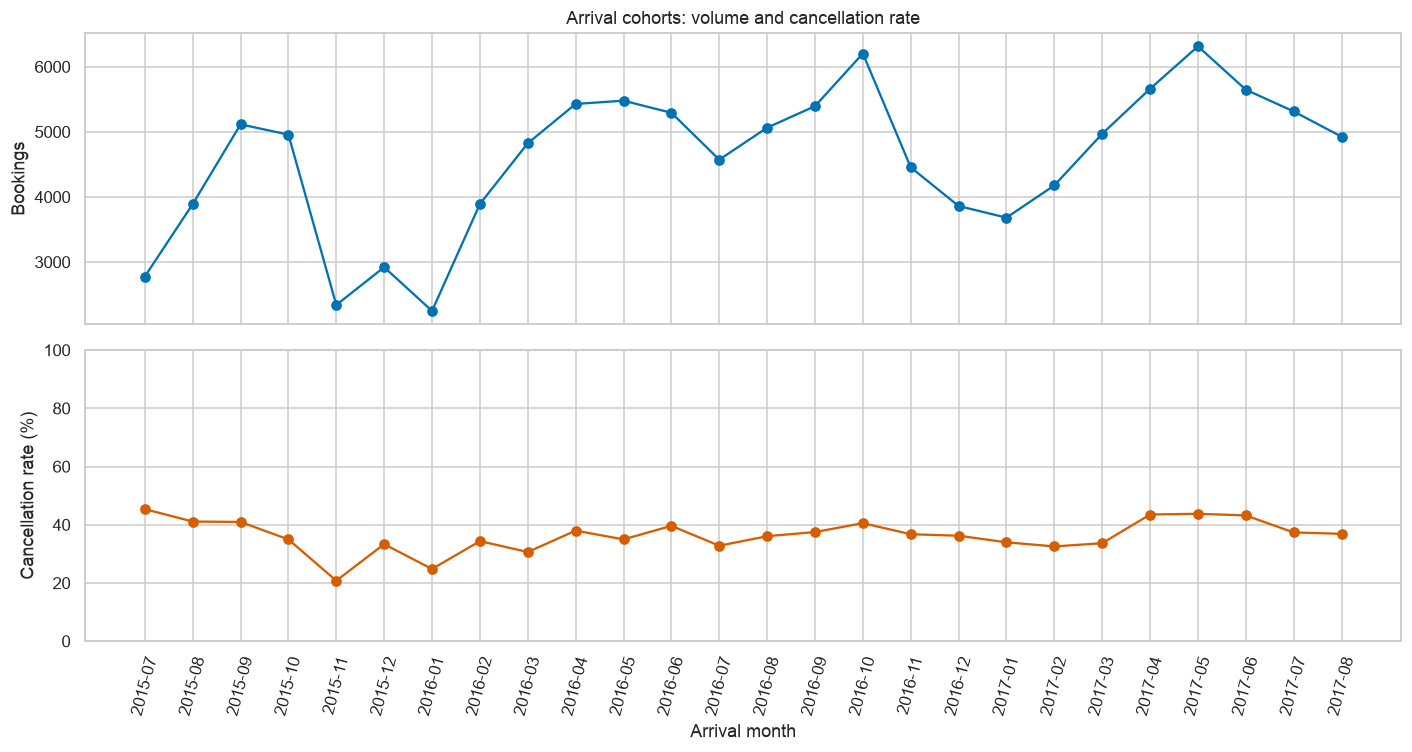

,bookings,canceled,cancellation_pct
arrival_month,,,
2015-07,2776,1259,45.35
2015-08,3889,1598,41.09
2015-09,5114,2094,40.95
2015-10,4957,1732,34.94
2015-11,2340,486,20.77
2015-12,2920,973,33.32
2016-01,2248,557,24.78
2016-02,3891,1337,34.36
2016-03,4824,1477,30.62


In [7]:
month_names = ['January','February','March','April','May','June','July','August','September','October','November','December']
month_number = df['arrival_date_month'].map({m:i+1 for i,m in enumerate(month_names)})
eda['arrival_date'] = pd.to_datetime(pd.DataFrame({'year':df['arrival_date_year'],
    'month':month_number,'day':df['arrival_date_day_of_month']}), errors='coerce')
print('Invalid arrival dates:', eda['arrival_date'].isna().sum())
print('Arrival range:', eda['arrival_date'].min(), 'to', eda['arrival_date'].max())
eda['arrival_month'] = eda['arrival_date'].dt.to_period('M').astype(str)
monthly = rate_table('arrival_month', eda)
monthly.to_csv(OUT / 'arrival_month_rates.csv')
fig, axes = plt.subplots(2,1,figsize=(13,7),sharex=True)
axes[0].plot(monthly.index, monthly['bookings'], marker='o'); axes[0].set_ylabel('Bookings')
axes[1].plot(monthly.index, monthly['cancellation_pct'], marker='o', color='#D55E00')
axes[1].set(ylabel='Cancellation rate (%)', ylim=(0,100), xlabel='Arrival month')
axes[1].tick_params(axis='x', rotation=75)
axes[0].set_title('Arrival cohorts: volume and cancellation rate')
save_show('07_arrival_cohorts')
display(monthly.round(2))

**Interpretation:** Arrival dates span July 2015–August 2017. Comparing total bookings for 2015 with 2016 would mix different observation lengths. Month-to-month changes may reflect hotel or segment mix as well as seasonality. Member 3 should discuss a chronological holdout with the team if the goal is predicting future bookings.

## 8. Relationships between predictors
**Question:** Which numeric variables move together? Pearson correlation captures linear association; it can miss nonlinear relationships. Identifier numbers, calendar codes and outcome-status fields are excluded from this heatmap.

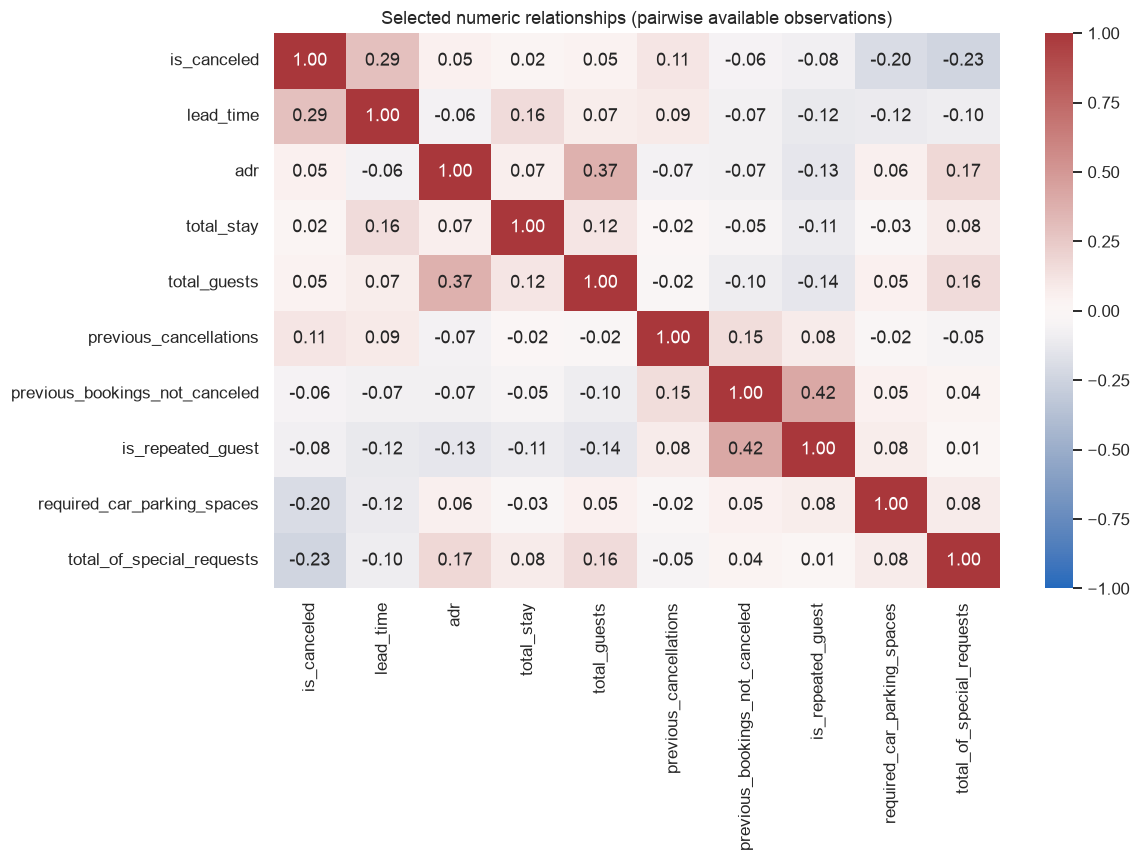

,pearson_r
total_of_special_requests,-0.234658
required_car_parking_spaces,-0.195498
is_repeated_guest,-0.084793
previous_bookings_not_canceled,-0.057358
total_stay,0.017779
total_guests,0.046506
adr,0.047557
previous_cancellations,0.110133
lead_time,0.293123


bookings  cancellation_rate
hotel        deposit_type                             
City Hotel   No Deposit       66442           0.304687
             Non Refund       12868           0.998135
             Refundable          20           0.700000
Resort Hotel No Deposit       38199           0.247389
             Non Refund        1719           0.959860
             Refundable         142           0.154930

In [8]:
correlation_columns = ['is_canceled','lead_time','adr','total_stay','total_guests',
    'previous_cancellations','previous_bookings_not_canceled','is_repeated_guest',
    'required_car_parking_spaces','total_of_special_requests']
corr = eda[correlation_columns].corr()
plt.figure(figsize=(11,8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='vlag', center=0, vmin=-1, vmax=1)
plt.title('Selected numeric relationships (pairwise available observations)')
save_show('08_correlations')
display(corr['is_canceled'].drop('is_canceled').sort_values().to_frame('pearson_r'))
# Stratify deposit patterns by hotel to check whether the pooled result hides differences.
display(df.groupby(['hotel','deposit_type'])['is_canceled'].agg(bookings='size', cancellation_rate='mean'))

**Interpretation:** Read the ranked correlation table alongside the categorical and lead-time charts. A small coefficient does not establish that a feature is useless. No feature is selected or discarded using this heatmap alone. Price, stay length and guest composition may interact; separate model validation is required.

## 9. Leakage review and team handover
**Question:** Would each candidate field be known when a new booking is scored? For discussion, assume prediction at initial reservation. The team must agree on the actual scoring time.

In [9]:
display(pd.crosstab(df['reservation_status'], df['is_canceled']))
leakage = pd.DataFrame([
    ('reservation_status / reservation_status_date', 'Exclude from predictors', 'Outcome status and its date are recorded downstream of the prediction.'),
    ('assigned_room_type / booking_changes / days_in_waiting_list', 'Timing review', 'May change or accumulate after the initial reservation.'),
    ('deposit_type / adr / total_of_special_requests / required_car_parking_spaces', 'Verify initial snapshot', 'Confirm values represent information available when scoring, not final booking state.'),
    ('previous_cancellations / previous_bookings_not_canceled / is_repeated_guest', 'Verify historical cutoff', 'History must contain only information available before the current booking.'),
    ('lead_time / hotel / market_segment / customer_type / reserved_room_type', 'Candidate features', 'Promising inputs subject to timing, quality and validation checks.'),
    ('agent / company / country', 'Meaning and encoding review', 'IDs are categorical; missingness and rare levels need investigation.')
], columns=['fields','recommendation','reason'])
display(leakage)
leakage.to_csv(OUT / 'feature_review.csv', index=False)

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


,fields,recommendation,reason
0,reservation_status / reservation_status_date,Exclude from predictors,Outcome status and its date are recorded downs...
1,assigned_room_type / booking_changes / days_in...,Timing review,May change or accumulate after the initial res...
2,deposit_type / adr / total_of_special_requests...,Verify initial snapshot,Confirm values represent information available...
3,previous_cancellations / previous_bookings_not...,Verify historical cutoff,History must contain only information availabl...
4,lead_time / hotel / market_segment / customer_...,Candidate features,"Promising inputs subject to timing, quality an..."
5,agent / company / country,Meaning and encoding review,IDs are categorical; missingness and rare leve...


**Member 2 — quality:** Investigate missing identifiers, repeated rows, zero guests/nights, negative and extreme ADR, and rare/undefined categories. Preserve an audit trail of cleaning decisions.

**Member 3 — preprocessing:** Split before fitting imputers, encoders or scalers. Discuss duplicate/group overlap across splits and a time-based evaluation. This notebook explores the full raw sample: do not use these full-sample findings to tune against a later claimed untouched test set. Freeze an evaluation set before model selection.

**Member 4 — features/leakage:** Exclude eventual reservation status and status date. Agree on scoring time and review the timing-sensitive fields above. Explore lead time, hotel, market segment and guest history. Total stay and total guests here are exploratory examples only; unknown child counts remain unknown in total guests.

**Member 1 — next stage:** Understand the agreed cleaning/pipeline decisions, then build Logistic Regression on the shared training data. Compare it fairly with the other three models using the same validation scheme.

**Limitations:** Observational data from two hotels in 2015–2017 cannot establish causation or represent all hotels today. Duplicates and unresolved quality issues can affect rates. Rare categories are unstable. A high predicted risk should support planning, not automatic rejection or penalties.

In [10]:
assert hashlib.sha256(DATA_PATH.read_bytes()).hexdigest() == raw_hash, 'Raw CSV changed.'
pd.testing.assert_frame_equal(df, pd.read_csv(DATA_PATH))
metadata = {'rows':len(df), 'columns':len(df.columns), 'raw_sha256':raw_hash,
            'python':sys.version.split()[0], 'pandas':pd.__version__,
            'numpy':np.__version__, 'matplotlib':matplotlib.__version__, 'seaborn':sns.__version__,
            'cancelled':int(df['is_canceled'].sum()),
            'cancellation_pct':float(df['is_canceled'].mean()*100)}
import json
(OUT / 'analysis_metadata.json').write_text(json.dumps(metadata, indent=2))
print('Completed. Raw file and dataframe unchanged. Outputs:', OUT)

Completed. Raw file and dataframe unchanged. Outputs: /Users/sbwaxan/Downloads/hotel-booking-cancellation 2/reports/member1
